# Iris Flower Clustering with K-Means

**Project:** Unsupervised learning, feature scaling, cluster selection, and evaluation.

This notebook clusters the 150-row Iris dataset using four numeric measurements. It demonstrates the elbow method, silhouette analysis, visualisation, and centroid-distance analysis. Species labels are used only after fitting the unsupervised model.


## 1. Imports and dataset


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
iris = load_iris(as_frame=True)
X = iris.data.copy()
y = iris.target  # For post-clustering interpretation only
species_names = iris.target_names
display(X.head())
print('Dataset shape:', X.shape)
print('Missing values per feature:\n', X.isna().sum())
display(X.describe().round(2))


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Dataset shape: (150, 4)
Missing values per feature:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


## 2. Explore petal measurements

This plot is exploratory. Species labels are not used to train K-Means.


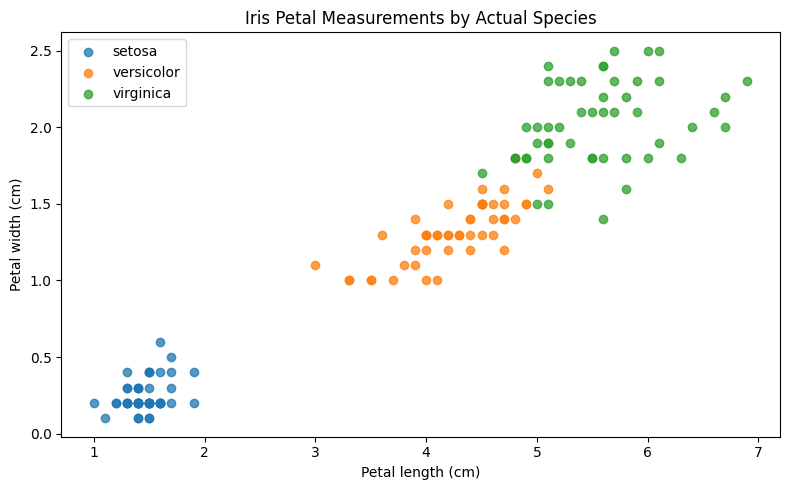

In [10]:
plt.figure(figsize=(8, 5))
for species_id, species_name in enumerate(species_names):
    mask = y == species_id
    plt.scatter(X.loc[mask, 'petal length (cm)'], X.loc[mask, 'petal width (cm)'], label=species_name, alpha=0.75)
plt.xlabel('Petal length (cm)'); plt.ylabel('Petal width (cm)')
plt.title('Iris Petal Measurements by Actual Species'); plt.legend(); plt.tight_layout(); plt.show()


## 3. Standardise features

K-Means uses Euclidean distances. Standardisation gives each feature approximately zero mean and unit variance. For a measurement x, the standardised value is z = (x − μ) / σ, where μ is that feature's mean and σ is its standard deviation. The species labels are excluded.


In [11]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
display(scaled_df.head().round(3))


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.901,1.019,-1.340,-1.315
1,-1.143,-0.132,-1.340,-1.315
2,-1.385,0.328,-1.397,-1.315
3,-1.507,0.098,-1.283,-1.315
4,-1.022,1.249,-1.340,-1.315


## 4. Elbow method

Inertia is the sum of squared distances from observations to their assigned centroids. It decreases as K increases; look for a bend where extra clusters provide diminishing returns. This is a heuristic, not a definitive test.


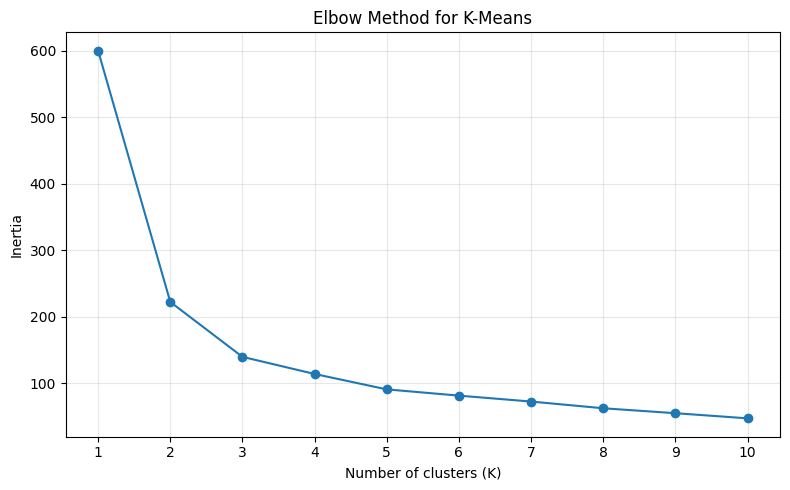

,K,Inertia
0,1,600.000
1,2,222.362
2,3,139.820
3,4,114.093
4,5,90.928
5,6,81.544
6,7,72.631
7,8,62.541
8,9,55.119
9,10,47.391


In [12]:
k_values = list(range(1, 11))
inertias = []
for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertias.append(model.inertia_)
plt.figure(figsize=(8, 5)); plt.plot(k_values, inertias, marker='o')
plt.xticks(k_values); plt.xlabel('Number of clusters (K)'); plt.ylabel('Inertia')
plt.title('Elbow Method for K-Means'); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()
display(pd.DataFrame({'K': k_values, 'Inertia': np.round(inertias, 3)}))


## 5. Silhouette analysis

The silhouette score ranges from −1 to 1. Higher values generally indicate more compact, well-separated clusters. Interpret it alongside the elbow curve and project objective.


,K,Silhouette score,Inertia
0,2,0.582,222.362
1,3,0.460,139.820
2,4,0.387,114.093
3,5,0.346,90.928
4,6,0.317,81.544


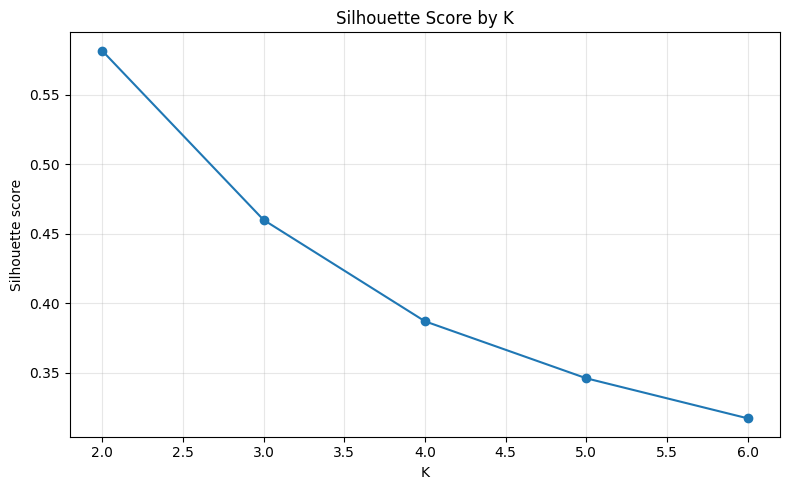

In [13]:
silhouette_results = []
for k in range(2, 7):
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = model.fit_predict(X_scaled)
    silhouette_results.append({'K': k, 'Silhouette score': silhouette_score(X_scaled, labels), 'Inertia': model.inertia_})
silhouette_df = pd.DataFrame(silhouette_results)
display(silhouette_df.round(3))
plt.figure(figsize=(8, 5)); plt.plot(silhouette_df['K'], silhouette_df['Silhouette score'], marker='o')
plt.xlabel('K'); plt.ylabel('Silhouette score'); plt.title('Silhouette Score by K')
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


## 6. Fit K-Means with K = 3 and visualise clusters

K=3 supports comparison with the three known species, but it is not necessarily the metric-optimal choice. The model uses all four scaled features; the plot is a two-dimensional projection.


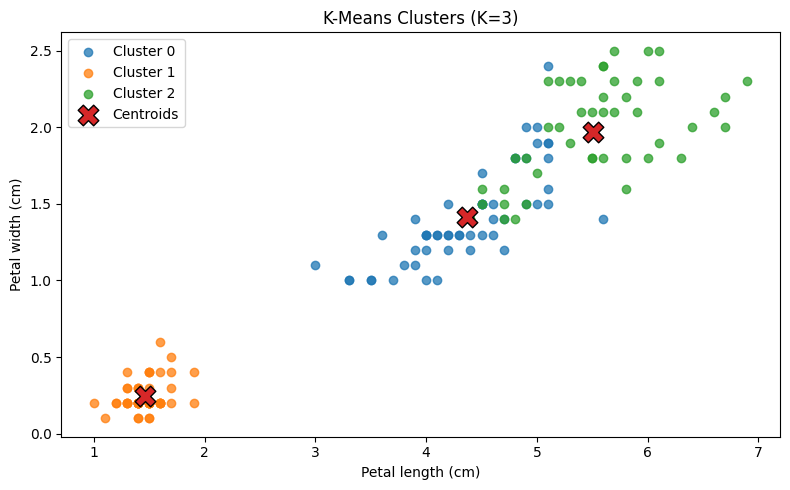

K=3 inertia: 139.82


In [14]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE)
labels = kmeans.fit_predict(X_scaled)
centres = scaler.inverse_transform(kmeans.cluster_centers_)
px = X.columns.get_loc('petal length (cm)'); py = X.columns.get_loc('petal width (cm)')
plt.figure(figsize=(8, 5))
for cluster_id in sorted(np.unique(labels)):
    mask = labels == cluster_id
    plt.scatter(X.loc[mask, 'petal length (cm)'], X.loc[mask, 'petal width (cm)'], label=f'Cluster {cluster_id}', alpha=0.75)
plt.scatter(centres[:, px], centres[:, py], marker='X', s=220, edgecolor='black', label='Centroids')
plt.xlabel('Petal length (cm)'); plt.ylabel('Petal width (cm)')
plt.title('K-Means Clusters (K=3)'); plt.legend(); plt.tight_layout(); plt.show()
print('K=3 inertia:', round(kmeans.inertia_, 3))


## 7. Distance to assigned centroid

Distance is calculated in standardised feature space. Larger distances indicate less typical points within their assigned cluster; they do not automatically mean a point is misclassified.


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Cluster,Distance to Centroid
41,4.5,2.3,1.3,0.3,1,2.671
15,5.7,4.4,1.5,0.4,1,2.399
131,7.9,3.8,6.4,2.0,2,2.173
117,7.7,3.8,6.7,2.2,2,2.101
60,5.0,2.0,3.5,1.0,0,1.972
33,5.5,4.2,1.4,0.2,1,1.877
118,7.7,2.6,6.9,2.3,2,1.831
14,5.8,4.0,1.2,0.2,1,1.639
32,5.2,4.1,1.5,0.1,1,1.577
93,5.0,2.3,3.3,1.0,0,1.533


,count,mean,median,max,std
Cluster,,,,,
0,53,0.857,0.805,1.972,0.323
1,50,0.814,0.723,2.671,0.545
2,47,0.913,0.877,2.173,0.432


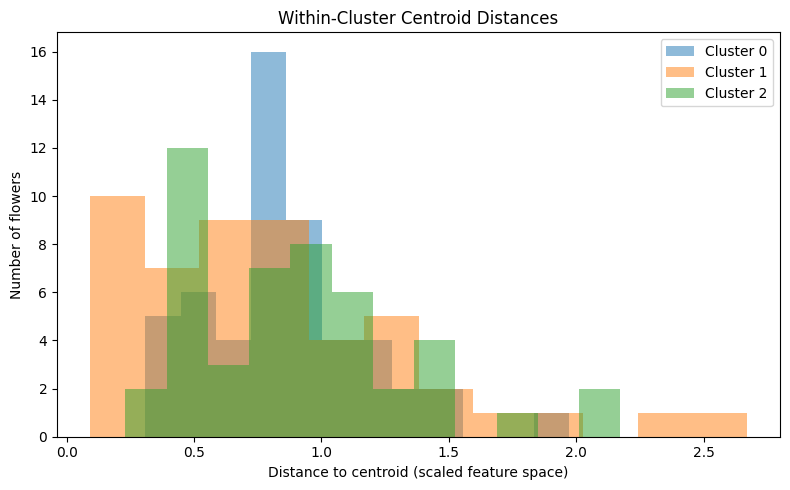

In [15]:
assigned_centres = kmeans.cluster_centers_[labels]
distances = np.linalg.norm(X_scaled - assigned_centres, axis=1)
distance_results = X.copy()
distance_results['Cluster'] = labels
distance_results['Distance to Centroid'] = distances
display(distance_results.sort_values('Distance to Centroid', ascending=False).head(10).round(3))
display(pd.DataFrame({'Cluster': labels, 'Distance': distances}).groupby('Cluster')['Distance'].agg(['count', 'mean', 'median', 'max', 'std']).round(3))
plt.figure(figsize=(8, 5))
for cluster_id in sorted(np.unique(labels)):
    plt.hist(distances[labels == cluster_id], bins=12, alpha=0.5, label=f'Cluster {cluster_id}')
plt.xlabel('Distance to centroid (scaled feature space)'); plt.ylabel('Number of flowers')
plt.title('Within-Cluster Centroid Distances'); plt.legend(); plt.tight_layout(); plt.show()


## 8. Post-clustering comparison with actual species

Species labels are used only after the model is fitted. Cluster IDs are arbitrary and do not map directly to species IDs.


K-Means Cluster,0,1,2
Actual Species,,,
setosa,0,50,0
versicolor,39,0,11
virginica,14,0,36


K-Means Cluster,0,1,2
Actual Species,,,
setosa,0.0,100.0,0.0
versicolor,78.0,0.0,22.0
virginica,28.0,0.0,72.0


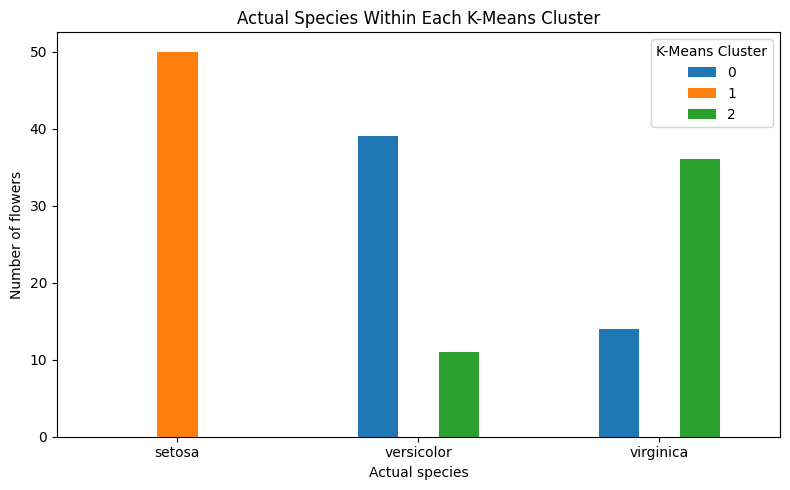

In [16]:
actual_species = pd.Series([species_names[i] for i in y], name='Actual Species')
comparison = pd.crosstab(actual_species, pd.Series(labels, name='K-Means Cluster'))
display(comparison)
display((comparison.div(comparison.sum(axis=1), axis=0) * 100).round(1))
comparison.plot(kind='bar', figsize=(8, 5))
plt.title('Actual Species Within Each K-Means Cluster'); plt.xlabel('Actual species'); plt.ylabel('Number of flowers')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()


## Conclusion

This workflow inspects and standardises data, compares cluster counts using inertia and silhouette scores, fits K-Means, visualises clusters, analyses centroid distances, and compares cluster assignments with known labels after fitting. Setosa is typically separated clearly, while Versicolor and Virginica can overlap. The elbow and silhouette criteria can favour different K values. Re-run the notebook to calculate current metrics for your installed library versions.

References: [Iris dataset](https://scikit-learn.org/stable/auto_examples/datasets/plot_iris_dataset.html) · [K-Means documentation](https://scikit-learn.org/stable/modules/clustering.html#k-means)
